(lecture12:homework)=
# Homework 12

+ Type your name and email in the "Student details" section below.
+ Develop the code and generate the figures you need to solve the problems using this notebook.
+ For the answers that require a mathematical proof or derivation you can either:
    
    - Type the answer using the built-in latex capabilities. In this case, simply export the notebook as a pdf and upload it on gradescope; or
    - You can print the notebook (after you are done with all the code), write your answers by hand, scan, turn your response to a single pdf, and upload on gradescope.

+ The total homework points are 100. Please note that the problems are not weighed equally.

```{note}
+ Please match all the pages corresponding to each of the questions when you submit on gradescope.
```

## Student details

+ **First Name: Dylan**
+ **Last Name: Rangel**
+ **Email: rangde01@purdue.edu**

In [99]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set(rc={"figure.dpi":100, 'savefig.dpi':300})
sns.set_context('notebook')
sns.set_style("ticks")
from IPython.display import set_matplotlib_formats
set_matplotlib_formats('retina', 'svg')
import numpy as np
import scipy.stats as st

/tmp/ipykernel_555/122018214.py:8: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  set_matplotlib_formats('retina', 'svg')


(lecture12:homework:problem2)=
## Problem 1 - Comparing performance of robotic systems

You are considering purchasing a robotic system for manufacturing masks.
There are two possibilities, say $A$ and $B$.
They both produce the same number of masks per day, they cost the same to purchase, and the have the same power and supply costs.
However, they are not identical. They have different faulty mask rates.
Let $X_A$ and $X_B$ be the number of faulty masks you get from each system, respectively, in a given day.
For each of the possibilities below:

1) Use `scipy.stats` to make two Normal random variables $X_A$ and $X_B$ with the right mean and variance.

2) Plot the PDF of the random variables in the same figure.

3) Find a 95% central credible interval.

3) Indicate which robotic system you would buy and why (three choices $A$, $B$, and ``I cannot choose'').


+ **Case 1:** $\mathbf{E}[X_A] = 1, \mathbf{V}[X_A] = 0.1$ and $\mathbf{E}[X_B] = 1, \mathbf{V}[X_B] = 0.2$.

**Answer:**

In [100]:
# Make the random variables here
XA = st.norm(loc=1,
             scale=np.sqrt(0.1))
XB = st.norm(loc=1,
             scale=np.sqrt(0.2))

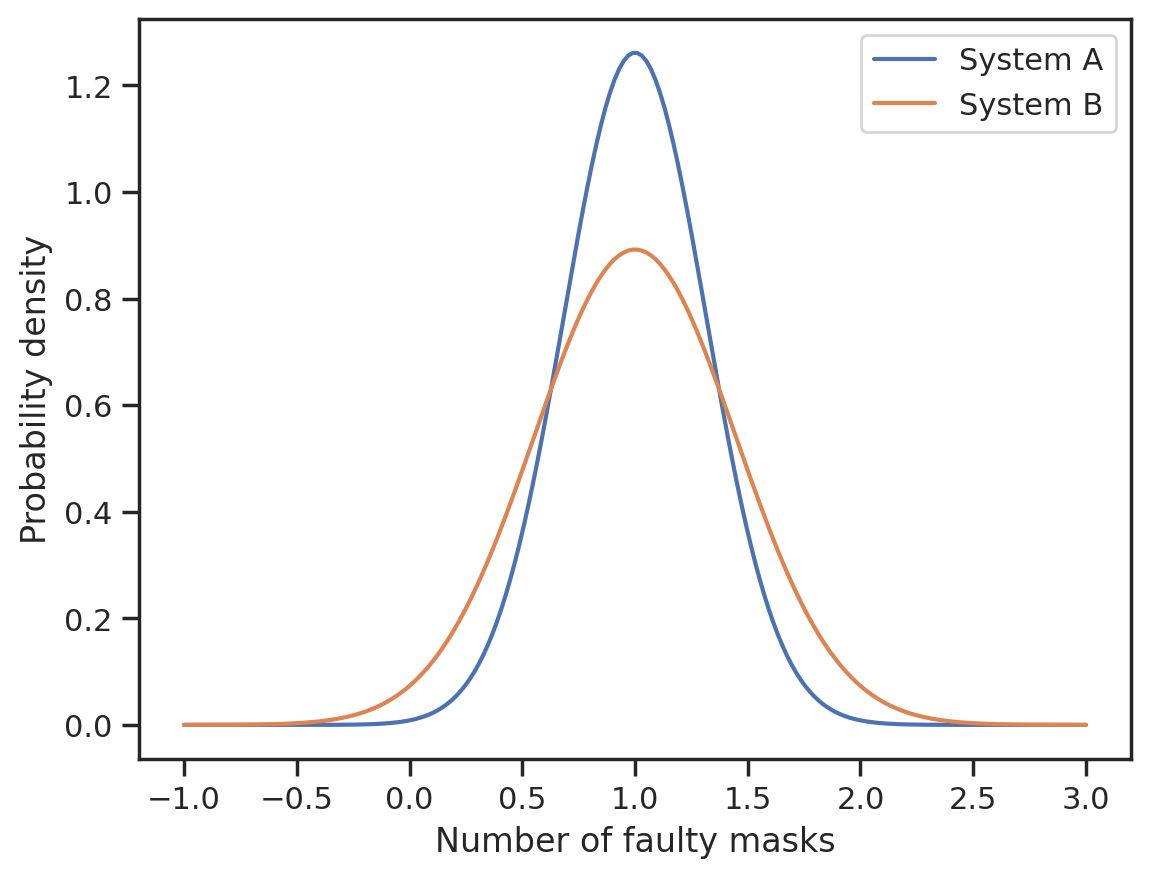

In [101]:
# Plot the PDF's here
xs = np.linspace(-1, 3, 200)

fig, ax = plt.subplots()
ax.plot(xs, XA.pdf(xs), label='System A')
ax.plot(xs, XB.pdf(xs), label='System B')
ax.set_xlabel('Number of faulty masks')
ax.set_ylabel('Probability density')
ax.legend()
plt.show()

In [102]:
# Find the 95% central credible interval for XA here
XA.ppf(0.025), XA.ppf(0.975)

(np.float64(0.3802049676954383), np.float64(1.6197950323045616))

In [103]:
# Find the 95% central credible interval for XB here
XB.ppf(0.025), XB.ppf(0.975)

(np.float64(0.12347745942341826), np.float64(1.8765225405765815))

*Your answer to which one you would buy and why here.*

*I would choose System A because both have the same average, but A has a smaller variance, so it is more consistent.*

+ **Case 2:** $\mathbf{E}[X_A] = 1, \mathbf{V}[X_A] = 0.1$ and $\mathbf{E}[X_B] = 2, \mathbf{V}[X_B] = 0.1$.

**Answer:**

In [104]:
# Make the random variables here
XA = st.norm(loc=1,
             scale=np.sqrt(0.1))
XB = st.norm(loc=2,
             scale=np.sqrt(0.1))

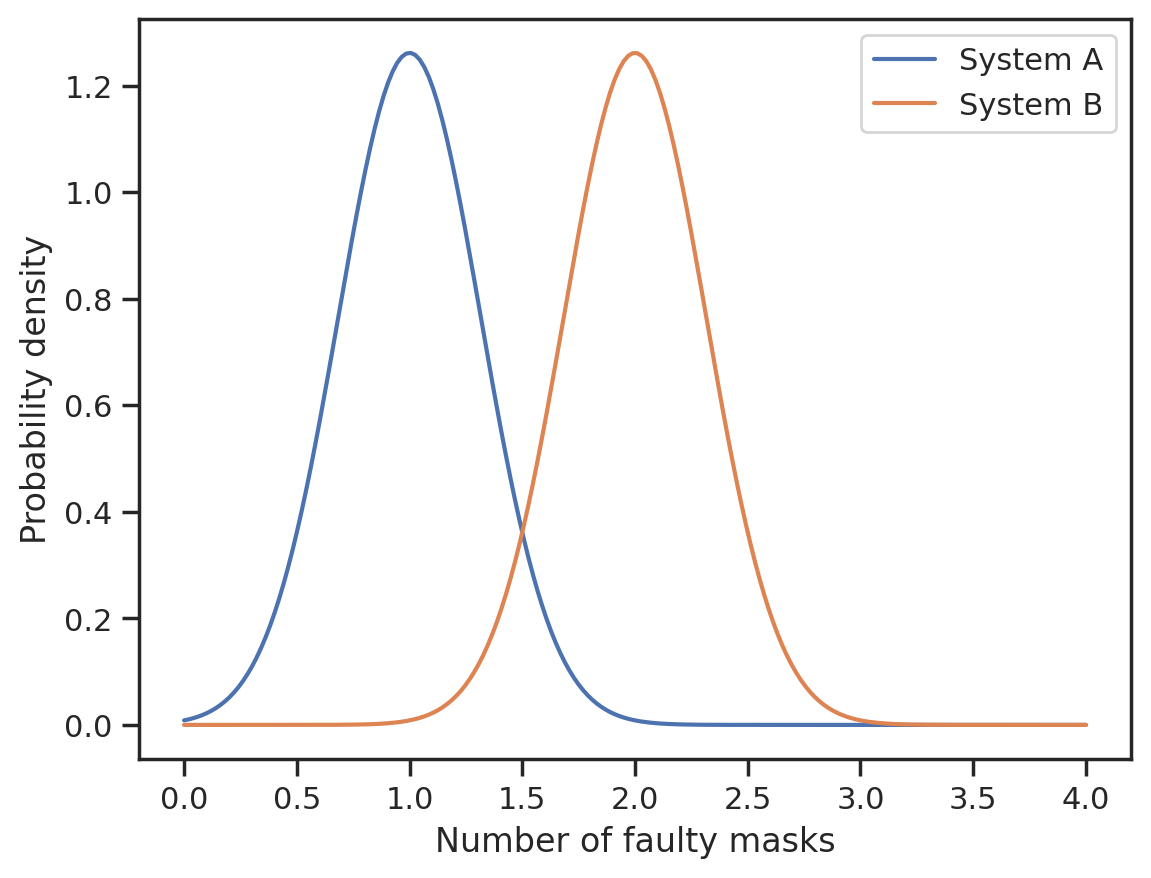

In [105]:
# Plot the PDF's here
xs = np.linspace(0, 4, 200)

fig, ax = plt.subplots()
ax.plot(xs, XA.pdf(xs), label='System A')
ax.plot(xs, XB.pdf(xs), label='System B')
ax.set_xlabel('Number of faulty masks')
ax.set_ylabel('Probability density')
ax.legend()
plt.show()

In [106]:
# Find the 95% central credible interval for XA here
XA.ppf(0.025), XA.ppf(0.975)

(np.float64(0.3802049676954383), np.float64(1.6197950323045616))

In [107]:
# Find the 95% central credible interval for XB here
XB.ppf(0.025), XB.ppf(0.975)

(np.float64(1.3802049676954384), np.float64(2.6197950323045616))

*Your answer to which one you would buy and why here.*

*I would choose System A because it produces fewer faulty masks on average, and both systems have the same variance.*

+ **Case 3:** $\mathbf{E}[X_A] = 1, \mathbf{V}[X_A] = 0.3$ and $\mathbf{E}[X_B] = 1.1, \mathbf{V}[X_B] = 0.1$.

**Answer:**

In [108]:
# Make the random variables here
XA = st.norm(loc=1,
             scale=np.sqrt(0.3))
XB = st.norm(loc=1.1,
             scale=np.sqrt(0.1))

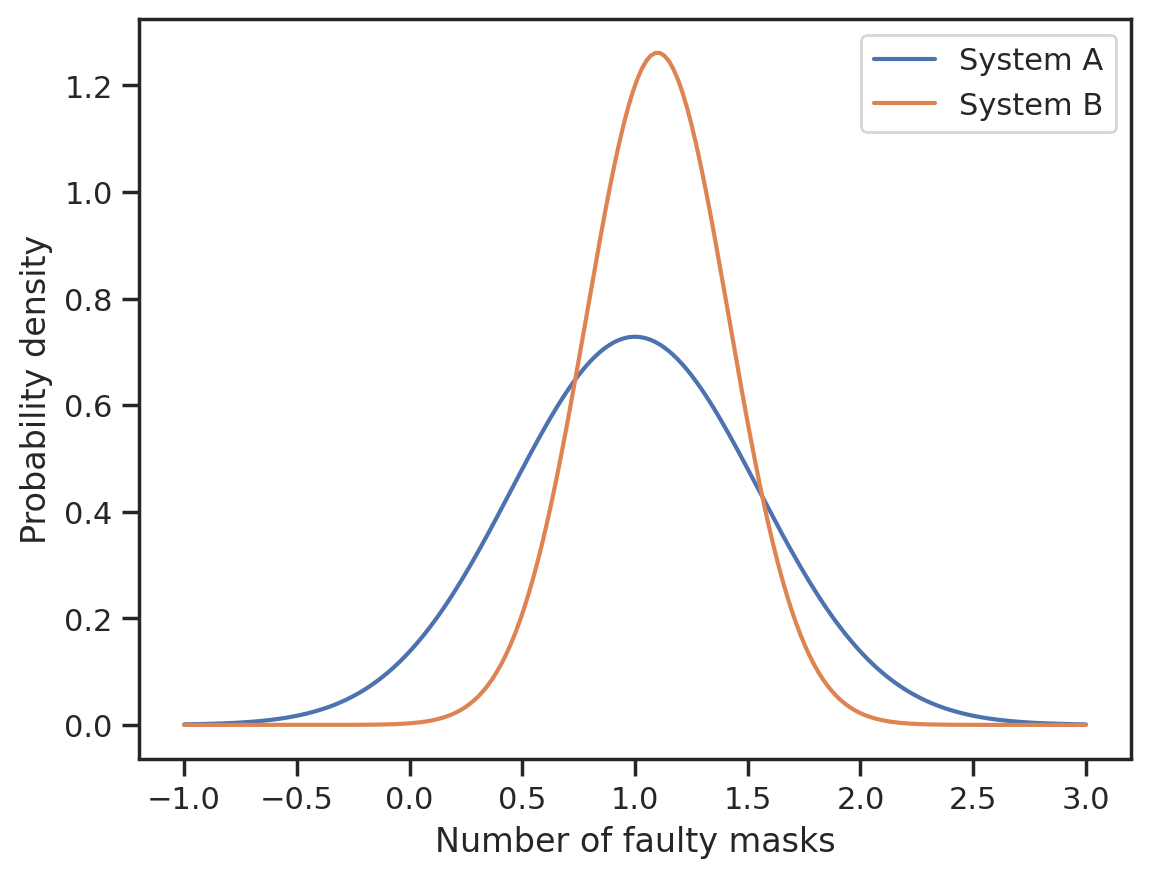

In [109]:
# Plot the PDF's here
xs = np.linspace(-1, 3, 200)

fig, ax = plt.subplots()
ax.plot(xs, XA.pdf(xs), label='System A')
ax.plot(xs, XB.pdf(xs), label='System B')
ax.set_xlabel('Number of faulty masks')
ax.set_ylabel('Probability density')
ax.legend()
plt.show()

In [110]:
# Find the 95% central credible interval for XA here
XA.ppf(0.025), XA.ppf(0.975)

(np.float64(-0.07351648623029439), np.float64(2.073516486230294))

In [111]:
# Find the 95% central credible interval for XA here
XB.ppf(0.025), XB.ppf(0.975)

(np.float64(0.4802049676954384), np.float64(1.7197950323045617))

*Your answer to which one you would buy and why here.*

*I cannot choose because System A has a lower average of faulty masks, but System B is more consistent. Both have their advantages.*

## Problem 2 - Figuring out which household conserves less energy

In this homework problem, we are going to look at a dataset for which the Normal is not a good fit.
In particular, we are going to look at HVAC energy consumption in our high-performance building data.

In [112]:
import requests
import os

# The url of the file we want to download
url = 'https://raw.githubusercontent.com/PurdueMechanicalEngineering/me-297-intro-to-data-science/master/data/temperature_raw.xlsx'
!curl -O $url

import numpy as np
import pandas as pd
df = pd.read_excel('temperature_raw.xlsx')
df = df.dropna(axis=0)
df.date = pd.to_datetime(df['date'], format='%Y-%m-%d')
df

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  277k  100  277k    0     0  1418k      0 --:--:-- --:--:-- --:--:-- 1425k


,household,date,score,t_out,t_unit,hvac
0,a1,2018-01-07,100.0,4.283373,66.693229,246.473231
1,a10,2018-01-07,100.0,4.283373,66.356134,5.492116
2,a11,2018-01-07,58.0,4.283373,71.549132,402.094327
3,a12,2018-01-07,64.0,4.283373,73.429514,211.692244
4,a13,2018-01-07,100.0,4.283373,63.923937,0.850536
...,...,...,...,...,...,...
5643,c44,2020-02-25,59.0,43.642388,76.494637,19.135139
5644,c45,2020-02-25,87.0,43.642388,71.165052,30.794281
5646,c47,2020-02-25,97.0,43.642388,68.603287,5.339391
5647,c48,2020-02-25,92.0,43.642388,73.429239,18.040078


+ Extract the `hvac` column for household `a5`:

In [113]:
hvac_a5 = df[df['household'] == 'a5']['hvac']
hvac_a5

,hvac
11,286.011150
61,137.786711
111,229.760337
161,79.433718
211,118.032515
...,...
5411,41.223938
5461,39.689817
5511,74.669721
5561,48.424783


+ Do the histogram of `hvac` for household `a5`:

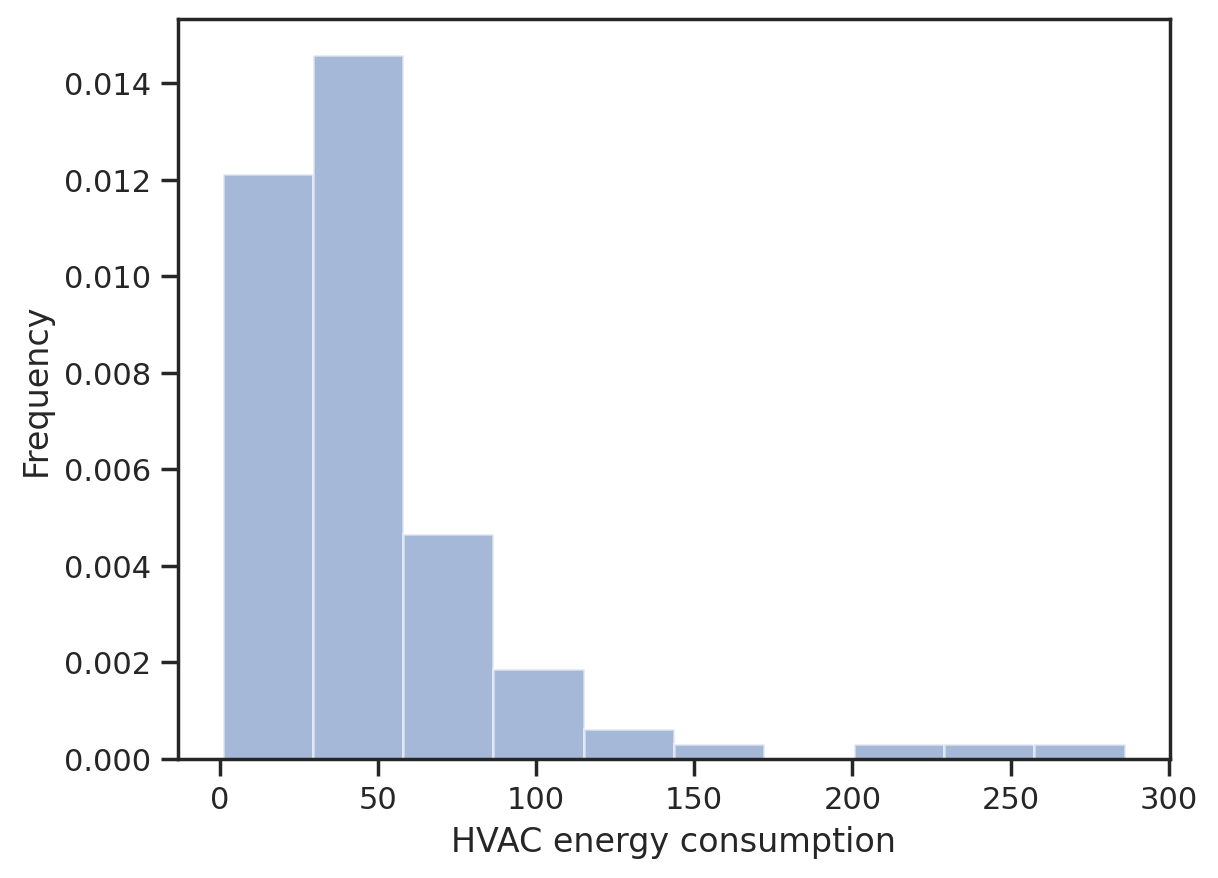

In [114]:
# Your code here
fig, ax = plt.subplots()
ax.hist(hvac_a5, density=True, alpha=0.5)
ax.set_xlabel('HVAC energy consumption')
ax.set_ylabel('Frequency')
plt.show()

+ Use the method of moments to fit a Normal distribution to the `hvac` data for household `a5`:

In [115]:
mu_a5 = hvac_a5.mean()
sigma2_a5 = np.mean(hvac_a5 ** 2) - mu_a5 ** 2
sigma_a5 = np.sqrt(sigma2_a5)

HVAC_a5 = st.norm(loc=mu_a5, scale=sigma_a5)

+ In the same figure, show the histogram of `hvac` data for household `a5` (use `density=True` to make sure itis normalized) and the PDF of the Normal you just fitted.
Is this a good fit? Why do you think we do not get a good fit?

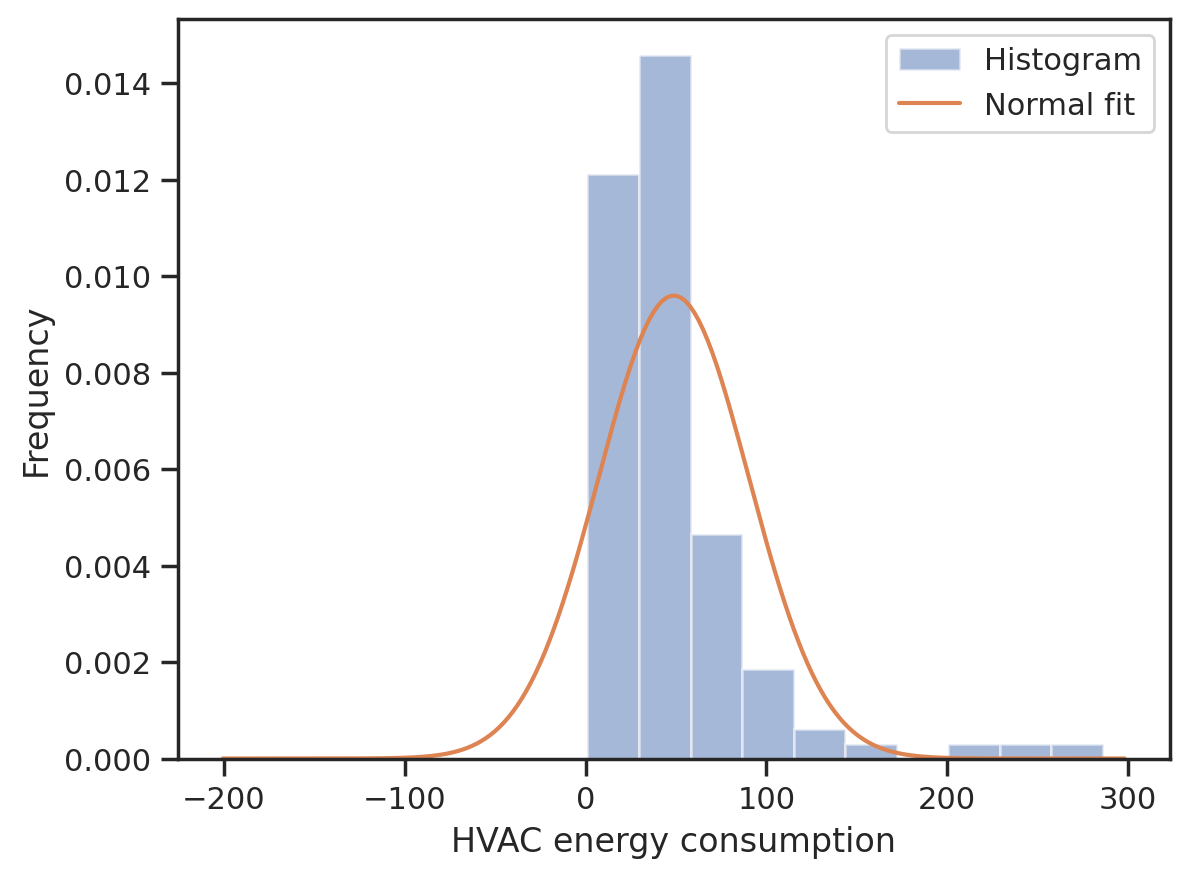

In [116]:
# Your code here
fig, ax = plt.subplots()
ax.hist(hvac_a5, density=True, alpha=0.5, label='Histogram')

xs = np.linspace(mu_a5 - 6*sigma_a5,
                 mu_a5 + 6*sigma_a5, 200)

ax.plot(xs, HVAC_a5.pdf(xs), label='Normal fit')
ax.set_xlabel('HVAC energy consumption')
ax.set_ylabel('Frequency')
ax.legend()
plt.show()

*Your answer here.*

*No, it is not a good fit because the data is skewed to the right, while a Normal distribution is symmetric.*

+ Now I am asking you to transform the data in a way that will make them look more Normal.
Do the histogram of the logarithm of the `hvac` data for household `a5`:

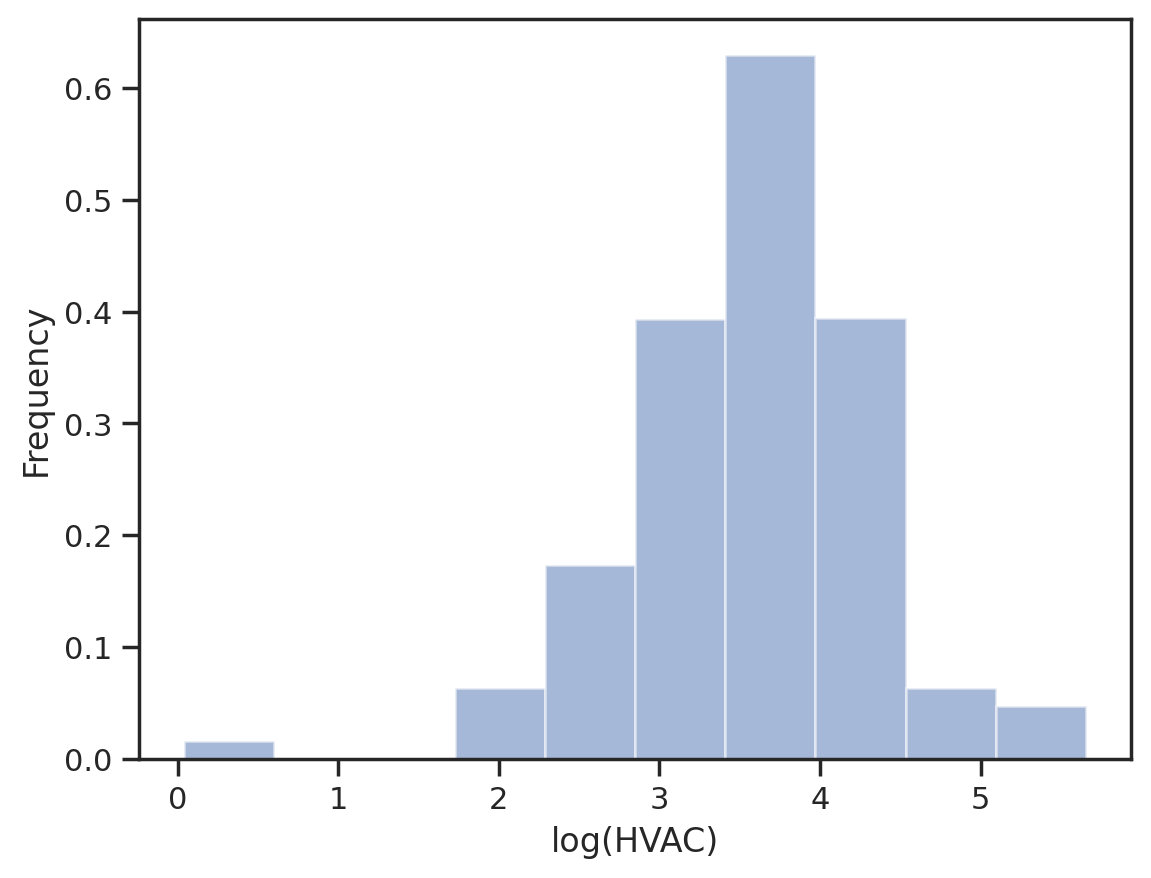

In [117]:
# your code here
log_hvac_a5 = np.log(hvac_a5[hvac_a5 > 0])

fig, ax = plt.subplots()
ax.hist(log_hvac_a5, density=True, alpha=0.5)
ax.set_xlabel('log(HVAC)')
ax.set_ylabel('Frequency')
plt.show()

+ Fit a Normal to the logarithm of the `hvac` data for household `a5`:

In [118]:
# your code here
mu_log_a5 = log_hvac_a5.mean()
sigma2_log_a5 = np.mean(log_hvac_a5 ** 2) - mu_log_a5 ** 2
sigma_log_a5 = np.sqrt(sigma2_log_a5)

LOG_HVAC_a5 = st.norm(loc=mu_log_a5,
                      scale=sigma_log_a5)

+ In the same figure, show the histogram of the **logarithm** of the `hvac` data for household `a5` and the PDF of the Normal you just fitted. Does this look like a good fit?

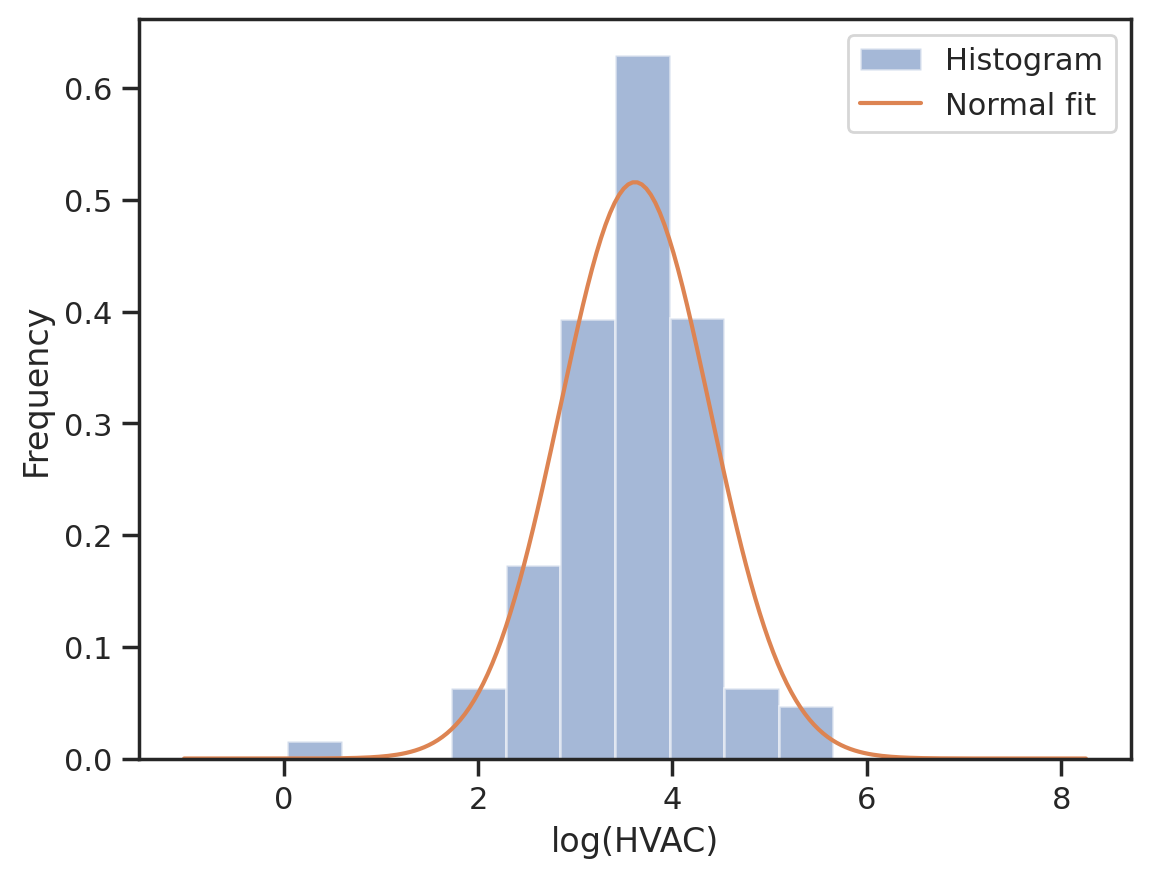

In [119]:
# Your code here
fig, ax = plt.subplots()
ax.hist(log_hvac_a5, density=True, alpha=0.5,
        label='Histogram')

xs = np.linspace(mu_log_a5 - 6*sigma_log_a5,
                 mu_log_a5 + 6*sigma_log_a5, 200)

ax.plot(xs, LOG_HVAC_a5.pdf(xs), label='Normal fit')
ax.set_xlabel('log(HVAC)')
ax.set_ylabel('Frequency')
ax.legend()
plt.show()

*Your answer here.*

*Yes, it is a better fit because taking the logarithm makes the data more symmetric and closer to a Normal distribution.*

+ Now do exactly the same thing as the previous bullet point for household `a3`.

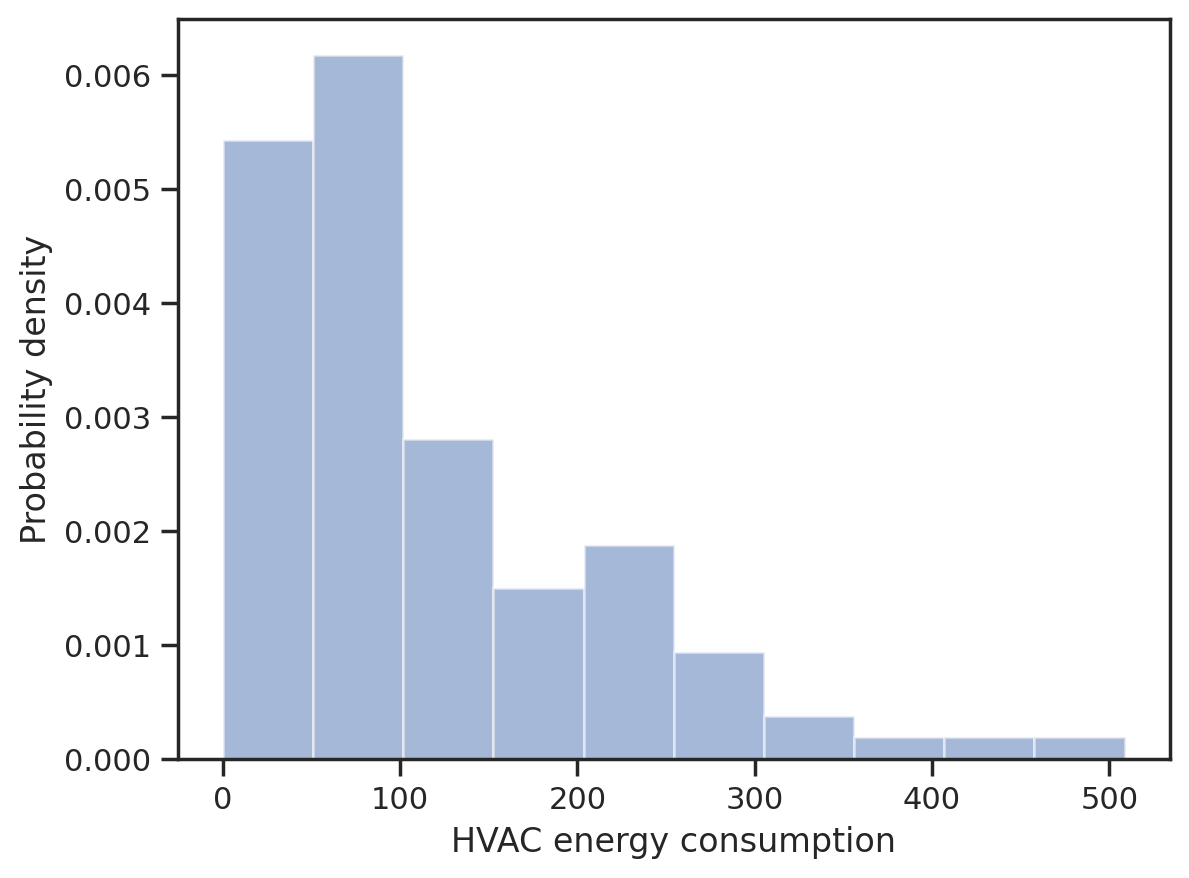

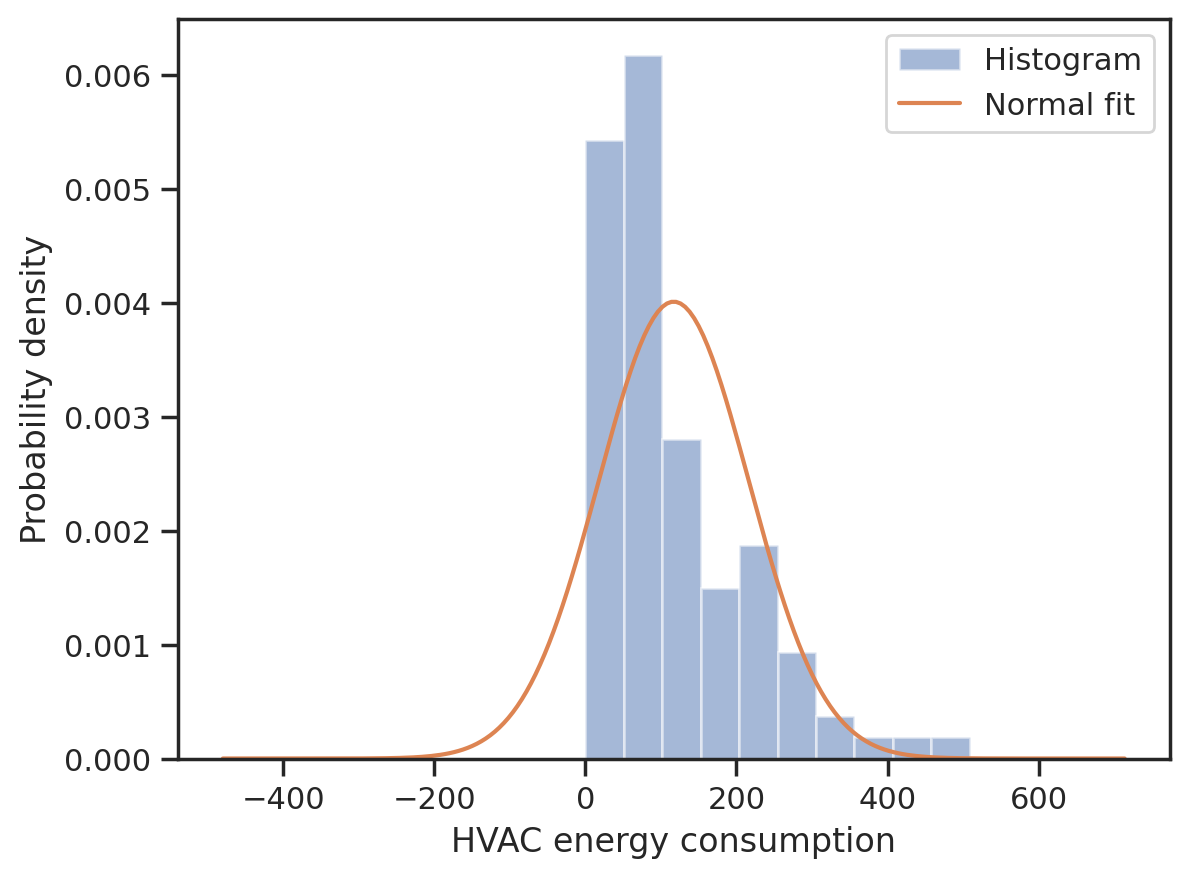

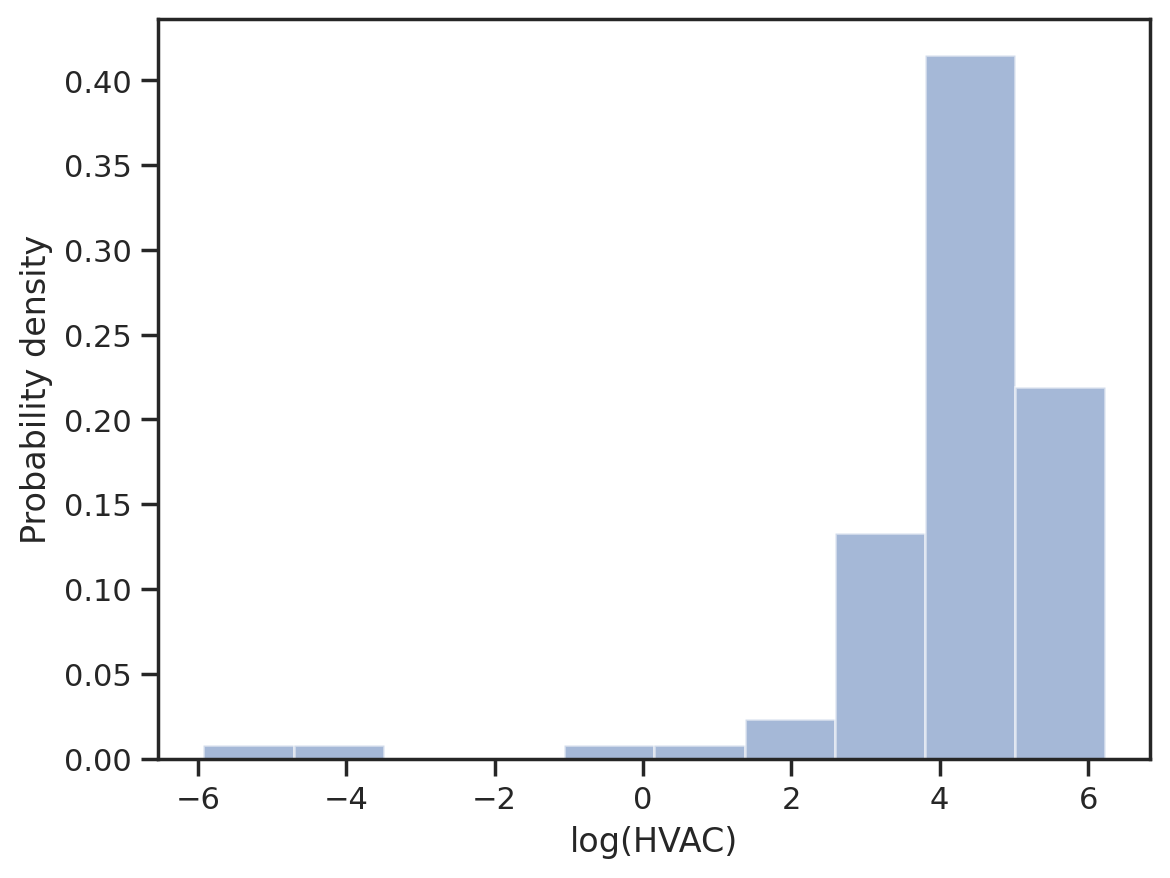

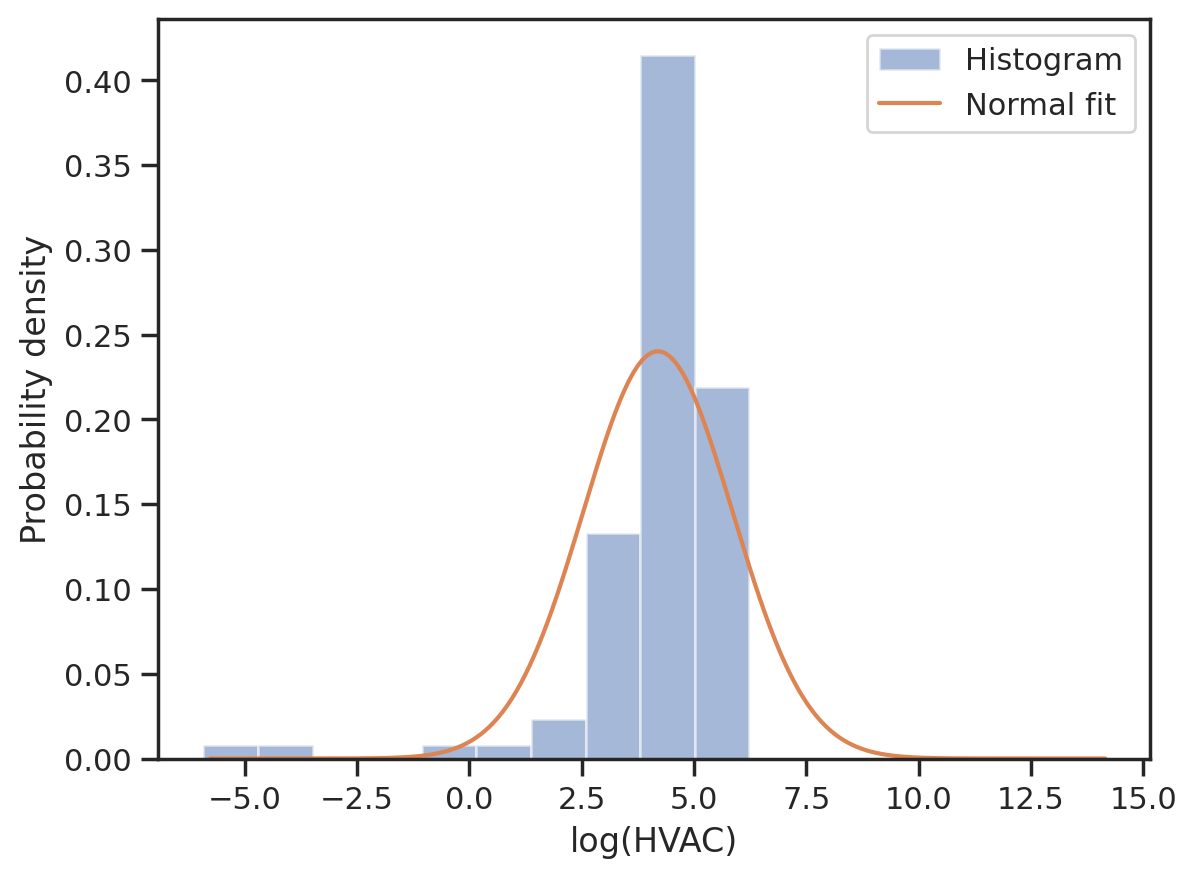

In [120]:
# Your code here - as many blocks as you like
hvac_a3 = df[df['household'] == 'a3']['hvac']

fig, ax = plt.subplots()
ax.hist(hvac_a3, density=True, alpha=0.5)
ax.set_xlabel('HVAC energy consumption')
ax.set_ylabel('Probability density')
plt.show()

mu_a3 = hvac_a3.mean()
sigma2_a3 = np.mean(hvac_a3 ** 2) - mu_a3 ** 2
sigma_a3 = np.sqrt(sigma2_a3)

HVAC_a3 = st.norm(loc=mu_a3, scale=sigma_a3)

fig, ax = plt.subplots()
ax.hist(hvac_a3, density=True, alpha=0.5, label='Histogram')

xs = np.linspace(mu_a3 - 6*sigma_a3,
                 mu_a3 + 6*sigma_a3, 200)

ax.plot(xs, HVAC_a3.pdf(xs), label='Normal fit')
ax.set_xlabel('HVAC energy consumption')
ax.set_ylabel('Probability density')
ax.legend()
plt.show()

log_hvac_a3 = np.log(hvac_a3[hvac_a3 > 0])

fig, ax = plt.subplots()
ax.hist(log_hvac_a3, density=True, alpha=0.5)
ax.set_xlabel('log(HVAC)')
ax.set_ylabel('Probability density')
plt.show()

mu_log_a3 = log_hvac_a3.mean()
sigma2_log_a3 = np.mean(log_hvac_a3 ** 2) - mu_log_a3 ** 2
sigma_log_a3 = np.sqrt(sigma2_log_a3)

LOG_HVAC_a3 = st.norm(loc=mu_log_a3, scale=sigma_log_a3)

fig, ax = plt.subplots()
ax.hist(log_hvac_a3, density=True, alpha=0.5, label='Histogram')

xs = np.linspace(mu_log_a3 - 6*sigma_log_a3,
                 mu_log_a3 + 6*sigma_log_a3, 200)

ax.plot(xs, LOG_HVAC_a3.pdf(xs), label='Normal fit')
ax.set_xlabel('log(HVAC)')
ax.set_ylabel('Probability density')
ax.legend()
plt.show()

+ Which household consumes more energy, `a5` or `a3`?

In [121]:
# Your code here - if needed
print('a5:', hvac_a5.mean())
print('a3:', hvac_a3.mean())


a5: 48.75363842428712
a3: 116.94555491534395


*Your answer here.*

*Household a3 consumes more energy because its average HVAC consumption is higher than a5.*

## Problem 3 - Introducing the Log-Normal distribution

In the previous problem, we took the logarithm of `hvac` in order to obtain a better fit to the Normal.
It turns out that this is a very common practice whenever you have a positive dataset that is skewed in the way we noticed above.
As a matter of fact, there is a distribution called the [Log-Normal distribution](https://en.wikipedia.org/wiki/Log-normal_distribution) which is designed to do exactly that.
Below, I show you could have fitted a Log-Normal distribution directly on the `hvac` data.

In [122]:
params = st.lognorm.fit(hvac_a5) # This does something similar to the method of moments
HVAC_a5_ln = st.lognorm(*params) # This is the random varibale
# Here is how you can sample from it:
HVAC_a5_ln.rvs(size=10)

array([ 49.38276998,  27.63407343,  27.34854625,  36.25035616,
        73.13030729,  31.86382646, 307.35326835,  51.57699611,
        71.21859365,  82.01075986])

In [123]:
# Here is how you can evaluate its PDF:
HVAC_a5_ln.pdf(200)

np.float64(0.00014185114943067792)

+ In the same figure, plot the PDF of the Log-normal along with the histogram of the `hvac` data for `a5`.

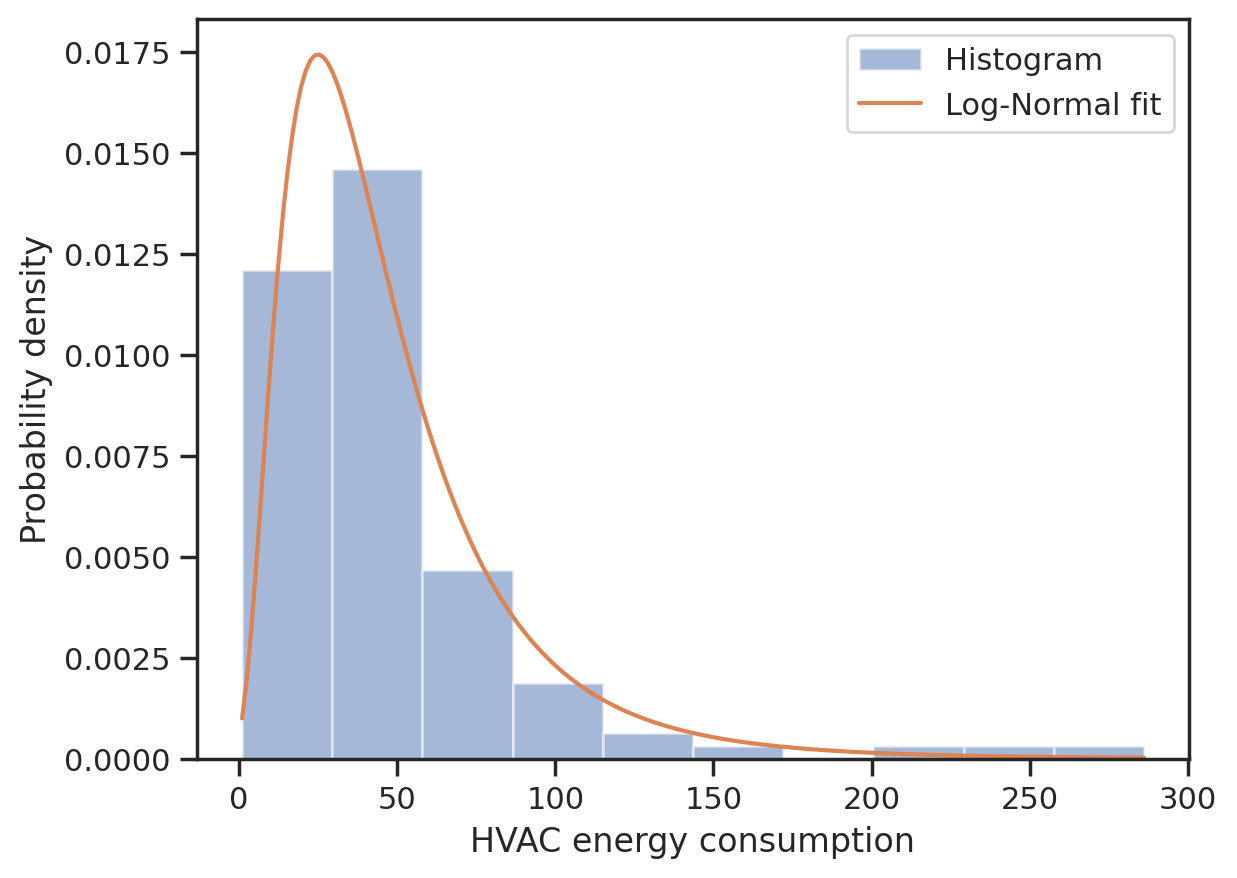

In [124]:
# Your code here - Plot the PDF of HVAC_a5_ln along with the histogram of hvac_a5.
fig, ax = plt.subplots()
ax.hist(hvac_a5, density=True, alpha=0.5, label='Histogram')

xs = np.linspace(hvac_a5.min(), hvac_a5.max(), 200)

ax.plot(xs, HVAC_a5_ln.pdf(xs), label='Log-Normal fit')
ax.set_xlabel('HVAC energy consumption')
ax.set_ylabel('Probability density')
ax.legend()
plt.show()

+ Is the fit with Log-Normal good?

*Your answer here.*

*Yes, it is a good fit because the Log-Normal curve follows the shape of the data and its right-skewed pattern.*

+ Recall how in [](lecture12:standard-normal-quantiles) we used the `ppf()` function of a random variable to find quantiles.
Use this function to find the 0.025-quantile of the Log-Normal we constructed above.

In [125]:
# Your code here
HVAC_a5_ln.ppf(0.025)

np.float64(7.491637161895099)

+ Now find the 95% central credible interval of the Log-Normal variable we constructed above.

In [126]:
# Your code here
HVAC_a5_ln.ppf(0.025), HVAC_a5_ln.ppf(0.975)

(np.float64(7.491637161895099), np.float64(142.8030915978453))

+ Repeat as many code-blocks as you need to fit a Log-Normal to the `hvac` data for household `a3` and then find the 95% central credible interval of the resulting random variable.

In [127]:
# Your code here
params_a3 = st.lognorm.fit(hvac_a3)
HVAC_a3_ln = st.lognorm(*params_a3)

HVAC_a3_ln.ppf(0.025), HVAC_a3_ln.ppf(0.975)

(np.float64(4.24293885683095), np.float64(418.6688283685003))

+ By comparing the 95% central credible intervals constructed above, which household `a5` or `a3` consumes more energy?

*Your answer here.*

*Household a3 consumes more energy because its 95% credible interval reaches much higher values than a5*

Run the following code to convert the notebook to a pdf. Verify that the file path to the notebook is correct.

In [128]:
#from google.colab import drive
#drive.mount('/content/drive')
#!apt-get install inkscape texlive texlive-xetex texlive-latex-extra pandoc --quiet
#!pip install pypandoc --quiet
#!jupyter nbconvert --to PDF '/content/drive/MyDrive/Colab Notebooks/Copy of homework_12.ipynb'